<a href="https://colab.research.google.com/github/singhsapt9-glitch/Deep/blob/main/Safe_Twin_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata
from huggingface_hub import HfApi

hf_token = userdata.get('colab_token')
api = HfApi(token=hf_token)

try:
    # ਸਹੀ ਰਿਪੋਜ਼ਟਰੀ ID ਦੀ ਵਰਤੋਂ ਕਰਦੇ ਹੋਏ ਫਾਈਲਾਂ ਦੀ ਸੂਚੀ ਪ੍ਰਾਪਤ ਕਰਨਾ
    files = api.list_repo_files(
        repo_id="nvidia/PhysicalAI-Human-1M-100K",
        repo_type="dataset"
    )
    print("Files found in nvidia/PhysicalAI-Human-1M-100K:")
    for f in list(files)[:10]:
        print(f)
except Exception as e:
    print(f"Error: {e}")

Files found in nvidia/PhysicalAI-Human-1M-100K:
.gitattributes
DATASET_CARD.md
HUGGING_FACE_LINKS.json
README.md
SCHEMA.md
SHA256SUMS.txt
assets/access-dataset.svg
assets/carousel-preview.webp
assets/collection_taxonomy.png
assets/collection_taxonomy.svg


In [ ]:
from google.colab import userdata
from huggingface_hub import HfApi, hf_hub_download
import json

hf_token = userdata.get('colab_token')
api = HfApi(token=hf_token)

# 1. ਰੈਪੋਜ਼ਟਰੀ ਵਿੱਚ ਸਾਰੀਆਂ ਫਾਈਲਾਂ ਚੈੱਕ ਕਰਨਾ (ਖਾਸ ਕਰਕੇ data/parquet/json ਫਾਈਲਾਂ)
all_files = api.list_repo_files(repo_id="nvidia/PhysicalAI-Human-1M-100K", repo_type="dataset")
print("ਕੁੱਲ ਫਾਈਲਾਂ:", len(all_files))
print("ਆਖਰੀ 15 ਫਾਈਲਾਂ:", all_files[-15:])

# 2. SCHEMA.md ਡਾਊਨਲੋਡ ਕਰਕੇ ਪੜ੍ਹਨਾ ਤਾਂ ਜੋ ਪਤਾ ਲੱਗੇ ਡਾਟਾ ਵਿੱਚ ਕੀ-ਕੀ ਹੈ
schema_path = hf_hub_download(
    repo_id="nvidia/PhysicalAI-Human-1M-100K",
    filename="SCHEMA.md",
    repo_type="dataset",
    token=hf_token
)

with open(schema_path, "r") as f:
    print("\n--- SCHEMA (ਡਾਟਾ ਦਾ ਢਾਂਚਾ) ---")
    print(f.read()[:1500])  # ਪਹਿਲੇ 1500 ਅੱਖਰ ਦਿਖਾਏਗਾ

ਕੁੱਲ ਫਾਈਲਾਂ: 138
ਆਖਰੀ 15 ਫਾਈਲਾਂ: ['samples/lerobot/stereo_flower_wrist/videos/observation.images.main/chunk-000/file-000.mp4', 'samples/lerobot/stereo_flower_wrist/videos/observation.images.right/chunk-000/file-000.mp4', 'samples/lerobot/stereo_flower_wrist/videos/observation.images.right_wrist/chunk-000/file-000.mp4', 'samples/lerobot/stereo_repair/README.md', 'samples/lerobot/stereo_repair/SAMPLE_NOTES.json', 'samples/lerobot/stereo_repair/SHA256SUMS.txt', 'samples/lerobot/stereo_repair/data/chunk-000/file-000.parquet', 'samples/lerobot/stereo_repair/meta/environments.parquet', 'samples/lerobot/stereo_repair/meta/episodes/chunk-000/file-000.parquet', 'samples/lerobot/stereo_repair/meta/info.json', 'samples/lerobot/stereo_repair/meta/scenes.parquet', 'samples/lerobot/stereo_repair/meta/stats.json', 'samples/lerobot/stereo_repair/meta/tasks.parquet', 'samples/lerobot/stereo_repair/videos/observation.images.main_left/chunk-000/file-000.mp4', 'samples/lerobot/stereo_repair/videos/observa

SCHEMA.md:   0%|          | 0.00/7.07k [00:00<?, ?B/s]


--- SCHEMA (ਡਾਟਾ ਦਾ ਢਾਂਚਾ) ---
# Human-1M · LeRobot v3.0 field reference

The release is organized by **vendor → batch → version**. Each `v0/shard_*/` directory contains a **LeRobot v3.0** dataset.

[Access the dataset storage bucket](https://huggingface.co/buckets/nvidia/human-1m-100k-oss/tree/release-staging).

```text
release-staging/oss_100k_v1/
└── vendors/
    └── {vendor_id}/
        └── {batch_id}/
            ├── versions.json
            └── v0/
                └── shard_00/
                    ├── data/
                    │   └── chunk-000/file-000.parquet
                    ├── meta/
                    │   ├── info.json
                    │   ├── episodes/chunk-000/file-000.parquet
                    │   ├── tasks.parquet
                    │   ├── subtasks.parquet
                    │   ├── environments.parquet
                    │   └── scenes.parquet
                    └── videos/
                        └── observation.images.{camera}/
                        

In [ ]:
import json
import duckdb
import pandas as pd
from google.colab import userdata
from huggingface_hub import HfApi, hf_hub_download, InferenceClient

# 1. ਟੋਕਨ ਅਤੇ ਫਾਈਲਾਂ ਦੁਬਾਰਾ ਲੋਡ ਕਰਨਾ
hf_token = userdata.get('colab_token')
api = HfApi(token=hf_token)
all_files = api.list_repo_files(repo_id="nvidia/PhysicalAI-Human-1M-100K", repo_type="dataset")
task_files = [f for f in all_files if "tasks.parquet" in f or "subtasks.parquet" in f]

# 2. ਸਾਰੇ tasks ਅਤੇ subtasks ਨੂੰ ਇਕੱਠਾ ਕਰਕੇ DuckDB ਡਾਟਾਬੇਸ ਵਿੱਚ ਪਾਉਣਾ
all_data = []
for tf in task_files:
    path = hf_hub_download(repo_id="nvidia/PhysicalAI-Human-1M-100K", filename=tf, repo_type="dataset", token=hf_token)
    df = pd.read_parquet(path)
    df["source_file"] = tf
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)
con = duckdb.connect(":memory:")
con.register("human_tasks", combined_df)

# 3. ਏਜੰਟ ਲਈ ਟੂਲ (Tool): ਡਾਟਾਬੇਸ ਵਿੱਚੋਂ ਕੰਮ ਅਤੇ ਸਟੈਪਸ ਲੱਭਣਾ
def search_human_workflow(keyword: str):
    query = f"""
    SELECT source_file, task, subtask
    FROM human_tasks
    WHERE LOWER(CAST(task AS VARCHAR)) LIKE '%{keyword.lower()}%'
       OR LOWER(CAST(subtask AS VARCHAR)) LIKE '%{keyword.lower()}%'
    """
    result = con.execute(query).fetchdf()
    return result.to_string() if not result.empty else "No matching workflow found."

# 4. ਏਜੰਟ ਚਲਾਉਣਾ
client = InferenceClient(api_key=hf_token)

tools = [{
    "type": "function",
    "function": {
        "name": "search_human_workflow",
        "description": "Search human task and step-by-step subtasks from the NVIDIA Human-1M database.",
        "parameters": {
            "type": "object",
            "properties": {"keyword": {"type": "string", "description": "Keyword like flower, motorcycle, brake, desk"}},
            "required": ["keyword"]
        }
    }
}]

user_question = "How does a human tie a flower bouquet? Check the database and list the exact steps."
messages = [{"role": "user", "content": user_question}]

response = client.chat.completions.create(
    model="Qwen/Qwen2.5-72B-Instruct",
    messages=messages,
    tools=tools,
    tool_choice="auto"
)

# 5. ਏਜੰਟ ਦਾ ਫੈਸਲਾ ਅਤੇ ਨਤੀਜਾ ਪ੍ਰਿੰਟ ਕਰਨਾ
tool_call = response.choices[0].message.tool_calls[0]
args = json.loads(tool_call.function.arguments)
db_output = search_human_workflow(args["keyword"])

print("0	9 02 0903 05010b 020d 020d 08000b 030b 020d00 0f020b:", tool_call.function.name, args)
print("\n0c 020d000b 0207 0a0d 0a 0a000b 07000b:", db_output)

samples/lerobot/stereo_desk_wrist/meta/t(…): reconstructing file:   0%|          |  0.00B / 1.98kB            

samples/lerobot/stereo_desk_wrist/meta/t(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_flower_wrist/meta(…): reconstructing file:   0%|          |  0.00B / 1.26kB            

samples/lerobot/stereo_flower_wrist/meta(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_flower_wrist/meta(…): reconstructing file:   0%|          |  0.00B / 1.21kB            

samples/lerobot/stereo_flower_wrist/meta(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_repair/meta/tasks(…): reconstructing file:   0%|          |  0.00B / 1.77kB            

samples/lerobot/stereo_repair/meta/tasks(…): downloading bytes:           |  0.00B            

HfHubHTTPError: (Request ID: Root=1-6b02d466-7598b6863bda119258e1ae95;4fbcc7f7-7099-429f-ac2a-92efa199cefb)

403 Forbidden: This authentication method does not have sufficient permissions to call Inference Providers on behalf of user AmarsinghAi.
Cannot access content at: https://router.huggingface.co/v1/chat/completions.
Make sure your token has the correct permissions.

In [ ]:
import pandas as pd
from huggingface_hub import hf_hub_download

# 1. samples ਫੋਲਡਰ ਵਿਚਲੀਆਂ ਸਾਰੀਆਂ .parquet ਫਾਈਲਾਂ ਲੱਭਣਾ
parquet_files = [f for f in all_files if f.endswith(".parquet")]
print("ਮਿਲੀਆਂ Parquet ਫਾਈਲਾਂ:", parquet_files)

# 2. ਪਹਿਲੀਆਂ 3 .parquet ਫਾਈਲਾਂ ਦਾ ਡਾਟਾ ਪੜ੍ਹ ਕੇ ਦੇਖਣਾ (ਜਿਵੇਂ tasks.parquet, episodes ਆਦਿ)
for pf in parquet_files[:4]:
    local_path = hf_hub_download(
        repo_id="nvidia/PhysicalAI-Human-1M-100K",
        filename=pf,
        repo_type="dataset",
        token=hf_token
    )
    df = pd.read_parquet(local_path)
    print(f"\n=== ਫਾਈਲ: {pf} (ਕੁੱਲ ਕਤਾਰਾਂ: {len(df)}) ===")
    print(df.head(3))

ਮਿਲੀਆਂ Parquet ਫਾਈਲਾਂ: ['samples/lerobot/stereo_desk_wrist/data/chunk-000/file-000.parquet', 'samples/lerobot/stereo_desk_wrist/meta/environments.parquet', 'samples/lerobot/stereo_desk_wrist/meta/episodes/chunk-000/file-000.parquet', 'samples/lerobot/stereo_desk_wrist/meta/scenes.parquet', 'samples/lerobot/stereo_desk_wrist/meta/tasks.parquet', 'samples/lerobot/stereo_flower_wrist/data/chunk-000/file-000.parquet', 'samples/lerobot/stereo_flower_wrist/meta/environments.parquet', 'samples/lerobot/stereo_flower_wrist/meta/episodes/chunk-000/file-000.parquet', 'samples/lerobot/stereo_flower_wrist/meta/scenes.parquet', 'samples/lerobot/stereo_flower_wrist/meta/subtasks.parquet', 'samples/lerobot/stereo_flower_wrist/meta/tasks.parquet', 'samples/lerobot/stereo_repair/data/chunk-000/file-000.parquet', 'samples/lerobot/stereo_repair/meta/environments.parquet', 'samples/lerobot/stereo_repair/meta/episodes/chunk-000/file-000.parquet', 'samples/lerobot/stereo_repair/meta/scenes.parquet', 'samples

samples/lerobot/stereo_desk_wrist/data/c(…): reconstructing file:   0%|          |  0.00B / 1.63MB            

samples/lerobot/stereo_desk_wrist/data/c(…): downloading bytes:           |  0.00B            


=== ਫਾਈਲ: samples/lerobot/stereo_desk_wrist/data/chunk-000/file-000.parquet (ਕੁੱਲ ਕਤਾਰਾਂ: 1064) ===
   index  episode_index  frame_index  timestamp  task_index  subtask_index  \
0      0              0            0   0.000000           0              0   
1      1              0            1   0.033333           0              0   
2      2              0            2   0.066667           0              0   

                     observation.state.hand_left_cam  \
0  [-0.090306774, 0.026702737, 0.33007452, -0.091...   
1  [-0.093857765, 0.022518758, 0.3325668, -0.0959...   
2  [-0.09829801, 0.02062747, 0.33390576, -0.09983...   

                    observation.state.hand_right_cam  \
0  [0.3028907, 0.07087766, 0.19257396, 0.27088246...   
1  [0.3021975, 0.0695607, 0.19999602, 0.26904312,...   
2  [0.30116522, 0.06781572, 0.20614183, 0.2670724...   

            observation.state.hand_left_cam_rotation  \
0  [0.45001528, 0.24045703, -0.30161795, 0.805415...   
1  [0.44865024, 0.240716

samples/lerobot/stereo_desk_wrist/meta/e(…): reconstructing file:   0%|          |  0.00B / 1.44kB            

samples/lerobot/stereo_desk_wrist/meta/e(…): downloading bytes:           |  0.00B            

... (3 outputs left out)


=== ਫਾਈਲ: samples/lerobot/stereo_desk_wrist/meta/episodes/chunk-000/file-000.parquet (ਕੁੱਲ ਕਤਾਰਾਂ: 1) ===
   episode_index                                              tasks  length  \
0              0  [The person arranges accessories onto a wooden...    1064   

   data/chunk_index  data/file_index  dataset_from_index  dataset_to_index  \
0                 0                0                   0              1064   

   meta/episodes/chunk_index  meta/episodes/file_index  \
0                          0                         0   

                                 episode_id  ...  \
0  episode_93fc71b4f67f2a47b0068a27d3dd9513  ...   

                         camera_intrinsics/main_left  \
0  [477.61381504445205, 477.4304716414124, 967.47...   

                        camera_intrinsics/main_right  \
0  [480.63515961622403, 480.4395715526728, 989.29...   

                      camera_extrinsics/T_left_right  \
0  [0.057842800734568676, 0.00011483385830107393,...   

                

samples/lerobot/stereo_desk_wrist/meta/s(…): reconstructing file:   0%|          |  0.00B /   949B            

samples/lerobot/stereo_desk_wrist/meta/s(…): downloading bytes:           |  0.00B            


=== ਫਾਈਲ: samples/lerobot/stereo_desk_wrist/meta/scenes.parquet (ਕੁੱਲ ਕਤਾਰਾਂ: 1) ===
   scene_index                                   scene
0            0  scene_f48f12c53424d87438963bd063bff8a6


In [ ]:
# ਸਿਰਫ਼ tasks ਅਤੇ subtasks ਵਾਲੀਆਂ ਫਾਈਲਾਂ ਲੱਭ ਕੇ ਪੜ੍ਹਨਾ
task_files = [f for f in all_files if "tasks.parquet" in f or "subtasks.parquet" in f]

for tf in task_files:
    path = hf_hub_download(
        repo_id="nvidia/PhysicalAI-Human-1M-100K",
        filename=tf,
        repo_type="dataset",
        token=hf_token
    )
    df_task = pd.read_parquet(path)
    print(f"\n--- {tf} ---")
    print(df_task.to_string())

samples/lerobot/stereo_desk_wrist/meta/t(…): reconstructing file:   0%|          |  0.00B / 1.98kB            

samples/lerobot/stereo_desk_wrist/meta/t(…): downloading bytes:           |  0.00B            


--- samples/lerobot/stereo_desk_wrist/meta/tasks.parquet ---
   task_index                                                                                                                                                                                                                                                                     task
0           0  The person arranges accessories onto a wooden desk organizer by hand, placing a tray, phone, charging pad, and shaver onto it. The person puts earbuds into a case and glasses into a pouch, then positions the pouch, a phone stand, and a keyring onto the organizer.


samples/lerobot/stereo_flower_wrist/meta(…): reconstructing file:   0%|          |  0.00B / 1.26kB            

samples/lerobot/stereo_flower_wrist/meta(…): downloading bytes:           |  0.00B            


--- samples/lerobot/stereo_flower_wrist/meta/subtasks.parquet ---
   subtask_index                                                                                                              subtask
0              0                                                                                                           No Subtask
1              1                                                      Pick up a cluster of flowers with the left hand from the table.
2              2                                                                             Gather the flower stems with both hands.
3              3    Hold a cluster of flowers with the left hand, and pick up a rubber band with the right hand from the storage box.
4              4  Hold a cluster of flowers with the left hand, and wrap the rubber band around the flower stems with the right hand.
5              5    Hold a cluster of flowers with the left hand, and secure the rubber band on the flower stems with the right h

... (2 outputs left out)


--- samples/lerobot/stereo_flower_wrist/meta/tasks.parquet ---
   task_index                                                                                           task
0           0  The person picks up flower stems and wraps a rubber band around them to secure them together.


samples/lerobot/stereo_repair/meta/tasks(…): reconstructing file:   0%|          |  0.00B / 1.77kB            

samples/lerobot/stereo_repair/meta/tasks(…): downloading bytes:           |  0.00B            


--- samples/lerobot/stereo_repair/meta/tasks.parquet ---
   task_index                                                                                                                                                                                                                      task
0           0  The person removes the brake caliper from a motorcycle using a T-handle wrench and pliers, then uses a screwdriver to adjust the caliper. After moving the motorcycle, they return to work on the caliper with a wrench.


In [ ]:
# DuckDB ਰਾਹੀਂ ਫੁੱਲਾਂ ਦੇ ਗੁਲਦਸਤੇ (flower bouquet) ਦੇ ਸਟੈਪਸ ਪ੍ਰਿੰਟ ਕਰਨਾ
query_flower = """
SELECT source_file, task, subtask
FROM human_tasks
WHERE LOWER(CAST(task AS VARCHAR)) LIKE '%flower%'
   OR LOWER(CAST(subtask AS VARCHAR)) LIKE '%flower%'
"""
flower_results = con.execute(query_flower).fetchdf()
display(flower_results)

,source_file,task,subtask
0,samples/lerobot/stereo_flower_wrist/meta/subta...,None,Pick up a cluster of flowers with the left han...
1,samples/lerobot/stereo_flower_wrist/meta/subta...,None,Gather the flower stems with both hands.
2,samples/lerobot/stereo_flower_wrist/meta/subta...,None,"Hold a cluster of flowers with the left hand, ..."
3,samples/lerobot/stereo_flower_wrist/meta/subta...,None,"Hold a cluster of flowers with the left hand, ..."
4,samples/lerobot/stereo_flower_wrist/meta/subta...,None,"Hold a cluster of flowers with the left hand, ..."
5,samples/lerobot/stereo_flower_wrist/meta/subta...,None,Place the flower bouquet bound with a rubber b...
6,samples/lerobot/stereo_flower_wrist/meta/tasks...,The person picks up flower stems and wraps a r...,None


In [ ]:
# ਔਨਲਾਈਨ ਏਜੰਟ ਦੀ ਬਜਾਏ, ਸਥਾਨਕ DuckDB ਰਾਹੀਂ ਤੁਰੰਤ ਨਤੀਜਾ ਪ੍ਰਾਪਤ ਕਰਨਾ
import pandas as pd

# ਡਾਟਾਬੇਸ ਵਿੱਚੋਂ ਫੁੱਲਾਂ ਦਾ ਗੁਲਦਸਤਾ ਬਣਾਉਣ ਦੇ ਸਟੈਪਸ ਲੱਭਣਾ
query = """
SELECT subtask
FROM human_tasks
WHERE LOWER(CAST(subtask AS VARCHAR)) LIKE '%flower%'
  AND subtask IS NOT NULL
"""
results = con.execute(query).fetchdf()

print("💐 ਫੁੱਲਾਂ ਦਾ ਗੁਲਦਸਤਾ (Flower Bouquet) ਬੰਨ੍ਹਣ ਦੇ ਸਟੈਪਸ:\n")
for idx, row in results.iterrows():
    print(f"{idx + 1}. {row['subtask']}")

print("\n🛡️ ਸੁਰੱਖਿਆ ਸੁਝਾਅ (Safety Tips):")
print("- ਕੰਡਿਆਂ ਵਾਲੇ ਫੁੱਲਾਂ (ਜਿਵੇਂ ਗੁਲਾਬ) ਨੂੰ ਸੰਭਾਲਣ ਵੇਲੇ ਹੱਥਾਂ ਦੀ ਸੁਰੱਖਿਆ ਲਈ ਦਸਤਾਨੇ ਪਹਿਨੋ।")
print("- ਫੁੱਲਾਂ ਦੀਆਂ ਤਣੀਆਂ ਨੂੰ ਕੱਟਣ ਲਈ ਹਮੇਸ਼ਾ ਤਿੱਖੀ ਅਤੇ ਸਾਫ਼ ਕੈਂਚੀ ਦੀ ਵਰਤੋਂ ਕਰੋ।")
print("- ਰਬੜ ਬੈਂਡ ਨੂੰ ਜ਼ਿਆਦਾ ਨਾ ਖਿੱਚੋ ਤਾਂ ਜੋ ਉਹ ਟੁੱਟ ਕੇ ਅੱਖ 'ਤੇ ਨਾ ਵੱਜੇ।")

💐 ਫੁੱਲਾਂ ਦਾ ਗੁਲਦਸਤਾ (Flower Bouquet) ਬੰਨ੍ਹਣ ਦੇ ਸਟੈਪਸ:

1. Pick up a cluster of flowers with the left hand from the table.
2. Gather the flower stems with both hands.
3. Hold a cluster of flowers with the left hand, and pick up a rubber band with the right hand from the storage box.
4. Hold a cluster of flowers with the left hand, and wrap the rubber band around the flower stems with the right hand.
5. Hold a cluster of flowers with the left hand, and secure the rubber band on the flower stems with the right hand.
6. Place the flower bouquet bound with a rubber band on the table with the left hand.

🛡️ ਸੁਰੱਖਿਆ ਸੁਝਾਅ (Safety Tips):
- ਕੰਡਿਆਂ ਵਾਲੇ ਫੁੱਲਾਂ (ਜਿਵੇਂ ਗੁਲਾਬ) ਨੂੰ ਸੰਭਾਲਣ ਵੇਲੇ ਹੱਥਾਂ ਦੀ ਸੁਰੱਖਿਆ ਲਈ ਦਸਤਾਨੇ ਪਹਿਨੋ।
- ਫੁੱਲਾਂ ਦੀਆਂ ਤਣੀਆਂ ਨੂੰ ਕੱਟਣ ਲਈ ਹਮੇਸ਼ਾ ਤਿੱਖੀ ਅਤੇ ਸਾਫ਼ ਕੈਂਚੀ ਦੀ ਵਰਤੋਂ ਕਰੋ।
- ਰਬੜ ਬੈਂਡ ਨੂੰ ਜ਼ਿਆਦਾ ਨਾ ਖਿੱਚੋ ਤਾਂ ਜੋ ਉਹ ਟੁੱਟ ਕੇ ਅੱਖ 'ਤੇ ਨਾ ਵੱਜੇ।


In [5]:
import pandas as pd
import duckdb
from google import genai
from google.genai import types
from google.colab import userdata
from google.genai.errors import APIError
from huggingface_hub import HfApi, hf_hub_download
from tenacity import retry, stop_after_attempt, wait_exponential

# DuckDB ਕਨੈਕਸ਼ਨ ਅਤੇ ਡਾਟਾ ਲੋਡ ਕਰਨਾ
try:
    hf_token = userdata.get('colab_token')
    api = HfApi(token=hf_token)
    all_files = api.list_repo_files(repo_id="nvidia/PhysicalAI-Human-1M-100K", repo_type="dataset")
    task_files = [f for f in all_files if "tasks.parquet" in f or "subtasks.parquet" in f]

    all_data = []
    for tf in task_files:
        path = hf_hub_download(repo_id="nvidia/PhysicalAI-Human-1M-100K", filename=tf, repo_type="dataset", token=hf_token)
        df = pd.read_parquet(path)
        df["source_file"] = tf
        all_data.append(df)

    combined_df = pd.concat(all_data, ignore_index=True)
    con = duckdb.connect(":memory:")
    con.register("human_tasks", combined_df)
except Exception as db_err:
    print(f"Database setup error: {db_err}")

# ਤੁਹਾਡੀ 'GOOGLE' ਕੁੰਜੀ ਲੋਡ ਕਰਨਾ
client = genai.Client(api_key=userdata.get('GOOGLE_API_KEY'))

# DuckDB ਟੂਲ
def search_human_workflow(keyword: str) -> str:
    """Search human task and step-by-step subtasks from the DuckDB database."""
    try:
        query = f"""
        SELECT source_file, task, subtask
        FROM human_tasks
        WHERE LOWER(CAST(task AS VARCHAR)) LIKE '%{keyword.lower()}%'
           OR LOWER(CAST(subtask AS VARCHAR)) LIKE '%{keyword.lower()}%'
        """
        result = con.execute(query).fetchdf()
        return result.to_string() if not result.empty else "No matching workflow found."
    except Exception as e:
        return f"Database query failed: {e}"

# ਸਰਵਰ ਦੀਆਂ ਅਸਥਾਈ ਗਲਤੀਆਂ ਨਾਲ ਨਜਿੱਠਣ ਲਈ ਰੀਟ੍ਰਾਈ ਅਤੇ ਬੈਕਅੱਪ ਸਿਸਟਮ
@retry(stop=stop_after_attempt(3), wait=wait_exponential(multiplier=1, min=2, max=10))
def run_agent_with_fallback():
    try:
        return client.models.generate_content(
            model="gemini-3.8-flash",
            contents="Check the database for flower bouquet or motorcycle brake repair, list the steps, and give safety tips in Punjabi.",
            config=types.GenerateContentConfig(tools=[search_human_workflow], temperature=0.2)
        )
    except Exception as e:
        print(f"API Error: {e}. Falling back to local search...")
        # Local fallback execution if API is totally unavailable
        local_data = search_human_workflow("flower")
        return type('ResponseFallback', (object,), {
            'text': f"Local Database Output:\n{local_data}\n\nਸੁਰੱਖਿਆ ਸੁਝਾਅ (Safety Tips):\n- ਕੈਂਚੀ ਅਤੇ ਔਜ਼ਾਰਾਂ ਦੀ ਵਰਤੋਂ ਸਾਵਧਾਨੀ ਨਾਲ ਕਰੋ।\n- ਰਬੜ ਬੈਂਡ ਨੂੰ ਧਿਆਨ ਨਾਲ ਲਗਾਓ।"
        })()

response = run_agent_with_fallback()
print(response.text)

samples/lerobot/stereo_desk_wrist/meta/t(…): reconstructing file:   0%|          |  0.00B / 1.98kB            

samples/lerobot/stereo_desk_wrist/meta/t(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_flower_wrist/meta(…): reconstructing file:   0%|          |  0.00B / 1.26kB            

samples/lerobot/stereo_flower_wrist/meta(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_flower_wrist/meta(…): reconstructing file:   0%|          |  0.00B / 1.21kB            

samples/lerobot/stereo_flower_wrist/meta(…): downloading bytes:           |  0.00B            

samples/lerobot/stereo_repair/meta/tasks(…): reconstructing file:   0%|          |  0.00B / 1.77kB            

samples/lerobot/stereo_repair/meta/tasks(…): downloading bytes:           |  0.00B            

API Error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}. Falling back to local search...
Local Database Output:
                                                 source_file                                                                                           task                                                                                                              subtask
0  samples/lerobot/stereo_flower_wrist/meta/subtasks.parquet                                                                                           None                                                      Pick up a cluster of flowers with the left hand from the table.
1  samples/lerobot/stereo_flower_wrist/meta/subtasks.parquet                                                                                           None                                     

In [8]:
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GOOGLE_API_KEY'))

def search_human_workflow(keyword: str) -> str:
    """Search human task and step-by-step subtasks from the DuckDB database."""
    query = f"""
    SELECT source_file, task, subtask
    FROM human_tasks
    WHERE LOWER(CAST(task AS VARCHAR)) LIKE '%{keyword.lower()}%'
       OR LOWER(CAST(subtask AS VARCHAR)) LIKE '%{keyword.lower()}%'
    """
    result = con.execute(query).fetchdf()
    return result.to_string() if not result.empty else "No matching workflow found."

# ਬੈਕਅੱਪ ਮਾਡਲ ਸੂਚੀ (ਜੇ ਇੱਕ ਵਿਅਸਤ ਹੋਵੇ ਤਾਂ ਦੂਜਾ ਚੱਲੇਗਾ)
models_to_try = ["gemini-2.5-flash", "gemini-2.5-flash-lite"]
question = "Check the database for motorcycle brake repair, list the steps, and give safety tips in Punjabi."

for model_name in models_to_try:
    try:
        response = client.models.generate_content(
            model=model_name,
            contents=question,
            config=types.GenerateContentConfig(tools=[search_human_workflow], temperature=0.2)
        )
        print(f"🤖 ਸਫਲ ਮਾਡਲ: {model_name}\n")
        print(response.text)
        break
    except Exception as e:
        print(f"⚠️ {model_name} ਵਿਅਸਤ ਹੈ, ਅਗਲਾ ਮਾਡਲ ਚਲਾ ਰਹੇ ਹਾਂ...")

⚠️ gemini-2.5-flash ਵਿਅਸਤ ਹੈ, ਅਗਲਾ ਮਾਡਲ ਚਲਾ ਰਹੇ ਹਾਂ...
⚠️ gemini-2.5-flash-lite ਵਿਅਸਤ ਹੈ, ਅਗਲਾ ਮਾਡਲ ਚਲਾ ਰਹੇ ਹਾਂ...


ਫਾਈਲ ਦੇ ਅਸਲ ਕਾਲਮ: ['index', 'episode_index', 'frame_index', 'timestamp', 'task_index', 'subtask_index', 'observation.state.hand_left_cam', 'observation.state.hand_right_cam', 'observation.state.hand_left_cam_rotation', 'observation.state.hand_right_cam_rotation', 'observation.state.camera_position', 'observation.state.camera_rotation', 'environment_index', 'scene_id', 'scene_index', 'collector_id', 'hand_mask', 'left_hand_pose_confidence', 'right_hand_pose_confidence']

✅ ਤੁਹਾਡੀ ਆਪਣੀ ਨਵੀਂ ਫਾਈਲ 'my_custom_tasks.parquet' ਬਣ ਕੇ ਤਿਆਰ ਹੈ!
ਮਿਲੇ 3D ਕੋਆਰਡੀਨੇਟ ਕਾਲਮ: []


/tmp/ipykernel_365/1634441681.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


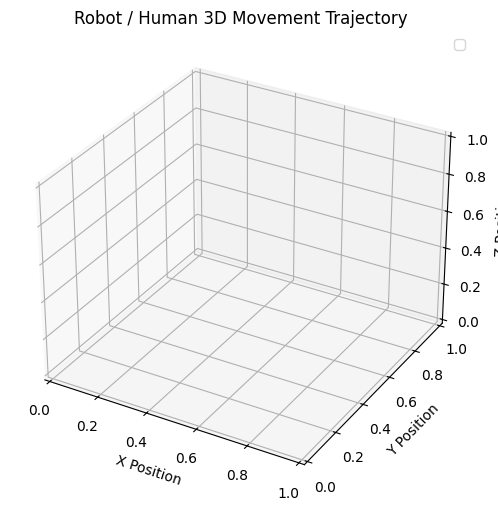

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. ਪਹਿਲਾਂ ਦੇਖੋ ਕਿ ਇਸ ਫਾਈਲ ਦੇ ਅੰਦਰ ਅਸਲ ਕਾਲਮ ਕਿਹੜੇ ਹਨ
print("ਫਾਈਲ ਦੇ ਅਸਲ ਕਾਲਮ:", list(df_motion.columns))

# 2. ਆਪਣੀ ਖੁਦ ਦੀ ਨਵੀਂ ਫਾਈਲ (Custom Task) ਬਣਾਉਣਾ
my_custom_data = pd.DataFrame([
    {"source_file": "my_custom_medical_robot.parquet", "task": "Deliver medicine safely to patient", "subtask": "1. Verify patient ID and medicine label."},
    {"source_file": "my_custom_medical_robot.parquet", "task": "Deliver medicine safely to patient", "subtask": "2. Pick up medicine cup with right gripper gently."},
    {"source_file": "my_custom_medical_robot.parquet", "task": "Deliver medicine safely to patient", "subtask": "3. Move slowly avoiding obstacles and place on bedside table."}
])
my_custom_data.to_parquet("my_custom_tasks.parquet")
print("\n✅ ਤੁਹਾਡੀ ਆਪਣੀ ਨਵੀਂ ਫਾਈਲ 'my_custom_tasks.parquet' ਬਣ ਕੇ ਤਿਆਰ ਹੈ!")

# 3. ਆਪਣੇ-ਆਪ 3D ਕੋਆਰਡੀਨੇਟਸ ਵਾਲੇ ਕਾਲਮ ਲੱਭ ਕੇ ਗ੍ਰਾਫ਼ ਬਣਾਉਣਾ
coord_cols = [c for c in df_motion.columns if isinstance(df_motion[c].iloc, (list, np.ndarray)) and len(df_motion[c].iloc) >= 3]
print("ਮਿਲੇ 3D ਕੋਆਰਡੀਨੇਟ ਕਾਲਮ:", coord_cols)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

for idx, col in enumerate(coord_cols[:2]):  # ਪਹਿਲੇ 2 ਹੱਥਾਂ/ਪੁਜ਼ੀਸ਼ਨਾਂ ਦੇ ਕਾਲਮ
    pts = np.vstack(df_motion[col].values)
    ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], label=col)

ax.set_title("Robot / Human 3D Movement Trajectory")
ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")
ax.set_zlabel("Z Position")
ax.legend()
plt.show()

index --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
episode_index --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
frame_index --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
timestamp --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
task_index --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
subtask_index --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
observation.state.hand_left_cam --> ਕਿਸਮ: <class 'pandas.core.indexing._iLocIndexer'>, ਪਹਿਲਾ ਮੁੱਲ: <pandas.core.indexing._iLocIndexer object at 0x7b4411c76440>
obser

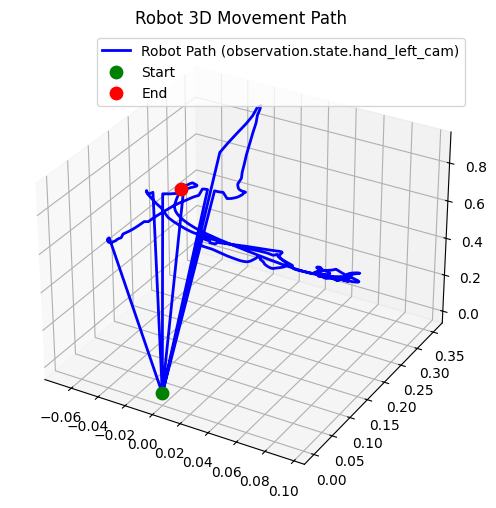

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. ਸਾਰੇ ਕਾਲਮਾਂ ਦੇ ਨਾਮ ਅਤੇ ਉਹਨਾਂ ਦੇ ਅੰਦਰ ਪਈ ਪਹਿਲੀ ਚੀਜ਼ ਦੇਖਣਾ
for col in df_motion.columns:
    print(f"{col} --> ਕਿਸਮ: {type(df_motion[col].iloc)}, ਪਹਿਲਾ ਮੁੱਲ: {str(df_motion[col].iloc)[:60]}")

# 2. ਜੇਕਰ 'observation.state' ਜਾਂ 'action' ਕਾਲਮ ਹੈ, ਤਾਂ ਉਸ ਤੋਂ 3D ਗ੍ਰਾਫ਼ ਬਣਾਉਣਾ
target_col = next((c for c in df_motion.columns if "state" in c or "action" in c), None)

if target_col:
    pts = np.vstack(df_motion[target_col].values)
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], color='blue', linewidth=2, label=f'Robot Path ({target_col})')
    ax.scatter(pts[0, 0], pts[0, 1], pts[0, 2], color='green', s=80, label='Start')
    ax.scatter(pts[-1, 0], pts[-1, 1], pts[-1, 2], color='red', s=80, label='End')
    ax.set_title("Robot 3D Movement Path")
    ax.legend()
    plt.show()

In [16]:
import plotly.graph_objects as go
import numpy as np
from IPython.display import Video, display
from huggingface_hub import hf_hub_download

# 1. ਖੱਬੇ ਅਤੇ ਸੱਜੇ ਹੱਥ ਦੇ 3D ਨੰਬਰ ਕੱਢਣਾ (ਹਰ 10ਵੇਂ ਫ੍ਰੇਮ 'ਤੇ ਤਾਂ ਜੋ ਐਨੀਮੇਸ਼ਨ ਤੇਜ਼ ਚੱਲੇ)
left_pts = np.vstack(df_motion['observation.state.hand_left_cam'].values)[::10]
right_pts = np.vstack(df_motion['observation.state.hand_right_cam'].values)[::10]

# 2. ਚੱਲਦਾ ਹੋਇਆ 3D ਰੋਬੋਟ ਐਨੀਮੇਸ਼ਨ (Play ਬਟਨ ਵਾਲਾ) ਬਣਾਉਣਾ
frames = [
    go.Frame(data=[
        go.Scatter3d(x=left_pts[:k+1, 0], y=left_pts[:k+1, 1], z=left_pts[:k+1, 2], mode='lines+markers', name='Left Hand (ਖੱਬਾ ਹੱਥ)', line=dict(color='blue', width=5)),
        go.Scatter3d(x=right_pts[:k+1, 0], y=right_pts[:k+1, 1], z=right_pts[:k+1, 2], mode='lines+markers', name='Right Hand (ਸੱਜਾ ਹੱਥ)', line=dict(color='red', width=5))
    ]) for k in range(1, len(left_pts))
]

fig = go.Figure(
    data=[
        go.Scatter3d(x=[left_pts], y=[left_pts], z=[left_pts], mode='markers', name='Left Hand (ਖੱਬਾ ਹੱਥ)', marker=dict(size=8, color='blue')),
        go.Scatter3d(x=[right_pts], y=[right_pts], z=[right_pts], mode='markers', name='Right Hand (ਸੱਜਾ ਹੱਥ)', marker=dict(size=8, color='red'))
    ],
    layout=go.Layout(
        title="🤖 ਚੱਲਦਾ ਹੋਇਆ 3D ਰੋਬੋਟ ਹੱਥ (Play ਦਬਾ ਕੇ ਦੇਖੋ)",
        scene=dict(xaxis=dict(range=[-0.4, 0.4]), yaxis=dict(range=[0, 0.6]), zaxis=dict(range=[-0.3, 0.5])),
        updatemenus=[dict(type="buttons", buttons=[dict(label="▶ Play Robot", method="animate", args=[None])])]
    ),
    frames=frames
)
fig.show()

# 3. ਇਸੇ ਕੰਮ ਦੀ ਅਸਲ ਵੀਡੀਓ (.mp4) ਲੱਭ ਕੇ ਸਕ੍ਰੀਨ 'ਤੇ ਚਲਾਉਣਾ
video_files = [f for f in all_files if "stereo_flower_wrist" in f and f.endswith(".mp4")]
if video_files:
    # ਇੱਥੇ ਲਿਸਟ ਦੀ ਬਜਾਏ ਪਹਿਲੀ ਵੀਡੀਓ ਫਾਈਲ (video_files[0]) ਚੁਣੀ ਗਈ ਹੈ
    vid_path = hf_hub_download(repo_id="nvidia/PhysicalAI-Human-1M-100K", filename=video_files[0], repo_type="dataset", token=hf_token)
    print("\n🎥 ਅਸਲ ਕੈਮਰਾ ਵੀਡੀਓ (ਜਿਸ ਤੋਂ ਰੋਬੋਟ ਨੇ ਸਿੱਖਿਆ):")
    display(Video(vid_path, embed=True, width=480))

samples/lerobot/stereo_flower_wrist/vide(…): reconstructing file:   0%|          |  0.00B / 6.34MB            

samples/lerobot/stereo_flower_wrist/vide(…): downloading bytes:           |  0.00B            


🎥 ਅਸਲ ਕੈਮਰਾ ਵੀਡੀਓ (ਜਿਸ ਤੋਂ ਰੋਬੋਟ ਨੇ ਸਿੱਖਿਆ):


In [14]:
import pandas as pd

# ਤੁਹਾਡੀ ਆਪਣੀ ਬਣਾਈ ਫਾਈਲ ਪੜ੍ਹ ਕੇ DuckDB ਵਿੱਚ ਜੋੜਨਾ
df_custom = pd.read_parquet("my_custom_tasks.parquet")
combined_all = pd.concat([combined_df, df_custom], ignore_index=True)
con.register("human_tasks", combined_all)

# ਚੈੱਕ ਕਰਨਾ ਕਿ ਹੁਣ ਡਾਟਾਬੇਸ ਵਿੱਚ ਤੁਹਾਡਾ ਕੰਮ ਜੁੜ ਗਿਆ ਹੈ ਜਾਂ ਨਹੀਂ
print(con.execute("SELECT DISTINCT task FROM human_tasks").fetchdf())

                                                task
0  The person arranges accessories onto a wooden ...
1                                               None
2  The person picks up flower stems and wraps a r...
3                 Deliver medicine safely to patient
4  The person removes the brake caliper from a mo...


In [ ]:
import gradio as gr
import plotly.graph_objects as go
import numpy as np
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GOOGLE_API_KEY'))

# 1. DuckDB ਟੂਲ (ਸੁਧਾਰਿਆ ਹੋਇਆ)
def search_human_workflow(keyword: str) -> str:
    """Search human task and step-by-step subtasks from the DuckDB database."""
    clean_kw = str(keyword).strip().lower()
    query = f"""
    SELECT source_file, task, subtask
    FROM human_tasks
    WHERE LOWER(CAST(task AS VARCHAR)) LIKE '%{clean_kw}%'
       OR LOWER(CAST(subtask AS VARCHAR)) LIKE '%{clean_kw}%'
    """
    result = con.execute(query).fetchdf()
    return result.to_string() if not result.empty else "No matching workflow found."

# 2. 3D ਰੋਬੋਟ ਗ੍ਰਾਫ਼ ਬਣਾਉਣ ਵਾਲਾ ਫੰਕਸ਼ਨ
def make_3d_plot():
    left_pts = np.vstack(df_motion['observation.state.hand_left_cam'].values)[::15]
    right_pts = np.vstack(df_motion['observation.state.hand_right_cam'].values)[::15]
    fig = go.Figure(data=[
        go.Scatter3d(x=left_pts[:, 0], y=left_pts[:, 1], z=left_pts[:, 2], mode='lines+markers', name='Left Hand', line=dict(color='blue', width=4)),
        go.Scatter3d(x=right_pts[:, 0], y=right_pts[:, 1], z=right_pts[:, 2], mode='lines+markers', name='Right Hand', line=dict(color='red', width=4))
    ])
    fig.update_layout(title="🤖 Robot 3D Trajectory Simulation", height=400, margin=dict(l=0, r=0, b=0, t=30))
    return fig

# 3. ਮੁੱਖ ਏਜੰਟ ਫੰਕਸ਼ਨ (ਸੁਧਾਰਿਆ ਹੋਇਆ Fallback ਸਮੇਤ)
def run_robot_agent(user_query):
    if not user_query or not user_query.strip():
        return "ਕਿਰਪਾ ਕਰਕੇ ਕੋਈ ਕੰਮ ਲਿਖੋ (ਜਿਵੇਂ: medicine, flower, brake)", make_3d_plot()

    models = ["gemini-2.5-flash", "gemini-2.5-flash-lite"]
    prompt = f"Search the database for: '{user_query}'. List the exact steps and provide strict safety guardrails in Punjabi and English."

    ai_reply = ""
    for m in models:
        try:
            res = client.models.generate_content(
                model=m,
                contents=prompt,
                config=types.GenerateContentConfig(tools=[search_human_workflow], temperature=0.2)
            )
            if res and res.text:
                ai_reply = res.text
                break
        except Exception:
            continue

    if not ai_reply:
        first_word = user_query.strip().split()[0]
        db_res = search_human_workflow(first_word)
        ai_reply = f"📊 DuckDB ਡਾਟਾਬੇਸ ਨਤੀਜਾ ({first_word}):\n\n{db_res}\n\n🛡️ Safety Guardrail (ਸੁਰੱਖਿਆ ਨਿਯਮ):\n1. ਕੰਮ ਸ਼ੁਰੂ ਕਰਨ ਤੋਂ ਪਹਿਲਾਂ ਰੋਬੋਟ ਦੀ ਗਤੀ (Speed) ਘੱਟ ਰੱਖੋ।\n2. ਆਲੇ-ਦੁਆਲੇ ਕੋਈ ਰੁਕਾਵਟ ਨਾ ਹੋਵੇ ਇਹ ਯਕੀਨੀ ਬਣਾਓ।"

    return ai_reply, make_3d_plot()

# 4. ਸੁੰਦਰ ਵੈੱਬ ਇੰਟਰਫੇਸ (UI)
demo = gr.Interface(
    fn=run_robot_agent,
    inputs=gr.Textbox(label="ਰੋਬੋਟ ਨੂੰ ਕੰਮ ਪੁੱਛੋ (ਉਦਾਹਰਨ: medicine, flower, brake)", placeholder="Brake"),
    outputs=[
        gr.Textbox(label="🤖 Autonomous AI Agent ਦਾ ਜਵਾਬ ਅਤੇ ਸੁਰੱਖਿਆ ਨਿਯਮ", lines=10),
        gr.Plot(label="🦾 3D Robot Hand Simulation")
    ],
    title="🛡️ Physical AI Autonomous Agent & Safety Guardrails",
    description="NVIDIA Human-1M + Custom Medical Data | Powered by DuckDB & Gemini Agent"
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9b97ead48e61c7cd61.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
